# Does the upstream moisture *pathway* -- its timing and spatial organization, not its box-mean magnitude -- explain ridge-building heat, and does that depend on season?

**Motivation.** `CA_ridging_persistence_ivt_seasonality.ipynb` tested whether upstream
NW-Pacific IVT *magnitude* has a seasonal "sweet spot" that would make March uniquely
effective at AR-fed ridge-building. It came back null on every angle, and the seasonal
premise was actually reversed (IVT magnitude rises, not falls, through Jan-Apr). That
notebook's own conclusion flagged what it couldn't test: Davis's documented mechanism for
March 2026 itself is not "elevated 5-day-mean IVT" but a **brief, concentrated, onset-phase
plume feeding diabatic heating into the ridge as it forms** -- a *pathway and timing*
question, not a magnitude-by-month question. `CA_ridging_persistence_central_pacific_template.ipynb`
independently found supporting evidence for a pathway-level effect: WY2026's four episodes'
precursor IVT spatial *patterns* were more similar to each other than a historical null
(91st percentile), even though their precursor dynamical (Z300) patterns weren't -- "closer
to Davis's own 'Anti-AR' framing... than a literal repeating wave template."

This notebook tests the pathway/timing angle directly, with two genuinely different
questions from the magnitude test, both zero-new-fetch (same `upstream_pacific_<year>.nc`
and `z500_t700_ca_<year>.nc` archives already in hand):

1. **Timing:** does upstream NW-Pacific moisture *lead* downstream CA ridge-building by a
   consistent lag (consistent with diabatic heating needing time to advect into and
   reinforce the ridge), and does that lag structure -- or its strength -- change by
   season?
2. **Spatial/temporal organization:** is the onset-window moisture transport a brief,
   concentrated pulse with a narrow, intense peak (an "AR-like" filament) rather than a
   steady, diffuse surge -- and does *that* organization, independent of mean magnitude,
   predict ridge/warm-episode intensity, and does its effectiveness vary by season?

As before, given this project's repeated box-placement-knife-edge history, both headline
results get a box-sensitivity sweep before being trusted.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal, percentileofscore
import statsmodels.formula.api as smf

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))
CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1
THRESHOLD_SD = 1

N_BOOT = 2000
rng = np.random.default_rng(42)

NWPAC_LAT, NWPAC_LON = slice(60, 40), slice(140, 180)   # same box as the magnitude-test notebook
AR_THRESH = 250   # kg/m/s -- a commonly used IVT intensity threshold for AR detection in
                  # the literature; used here only as a fixed yardstick for a relative
                  # (fraction-of-box-area) metric, not as a formal AR-detection algorithm
MONTH_NAME = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr'}
VAR_LABEL = {'500 hPa height (ridging)': 'Z500', '700 hPa temperature (warm)': 'T700'}


## 2. Load upstream IVT (gridded, cached) and the CA-box Z500/T700 standardized-anomaly series

Caches each year's full 2D IVT field (`yearly_ivt`) -- needed later for the spatial-
organization metrics -- and builds the box-mean NW-Pac daily IVT series from it. Z500/T700
daily standardized anomalies use this project's own canonical pipeline
(`lib.box_average_df` + `lib.standardize_with_trend`), identical to
`CA_z500_t700_blocking_events_detrend_5day.ipynb`'s Sections 1-2.

In [2]:
def box_mean_series(da, lat_slice, lon_slice=slice(None, None)):
    sub = da.sel(latitude=lat_slice, longitude=lon_slice)
    w = np.cos(np.deg2rad(sub.latitude))
    return sub.weighted(w).mean(dim=('latitude', 'longitude'))


def load_year_ivt(year):
    ds = xr.open_dataset(DATA_DIR / f'upstream_pacific_{year}.nc', engine='netcdf4')
    ds = ds[['viwve', 'viwvn']]
    ivt = np.sqrt(ds.viwve**2 + ds.viwvn**2)
    return ivt.load()


yearly_ivt = {y: load_year_ivt(y) for y in YEARS}

rows = []
for y, da in yearly_ivt.items():
    nwpac = box_mean_series(da, NWPAC_LAT, NWPAC_LON)
    rows.append(pd.Series(nwpac.values, index=pd.to_datetime(da.time.values)))
ivt_daily = pd.concat(rows).sort_index()
print(f'Loaded IVT for {len(yearly_ivt)} years; {len(ivt_daily)} total NW-Pac box-mean days')


Loaded IVT for 36 years; 4329 total NW-Pac box-mean days


In [3]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds = lib.open_yearly_dataset(files)
df = lib.box_average_df(ds, ['z500', 't700'])

sanom_daily = {}
for col in ['z500', 't700']:
    sanom, diag = lib.standardize_with_trend(df.index, df[col].values, window=CLIM_WINDOW,
                                              label=col, verbose=False)
    sanom_daily[col] = pd.Series(sanom, index=df.index)
print('Z500/T700 standardized-anomaly series built,', len(df), 'days')


Z500/T700 standardized-anomaly series built, 4329 days


In [4]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)
events['onset_month'] = pd.to_datetime(events.start_date).dt.month
events['sanom_col'] = events.variable.map({'500 hPa height (ridging)': 'z500', '700 hPa temperature (warm)': 't700'})
print(f'{len(events)} events at >= {THRESHOLD_SD} sigma:')
events.groupby('variable').size()


95 events at >= 1 sigma:


variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64

## 3. Timing: does upstream moisture lead downstream ridge-building by a consistent lag?

For each event, builds a day-aligned window (offset = days relative to onset, -10 to +20,
clipped at each year's Jan 1 floor / Apr 30 ceiling) of NW-Pac IVT and the matching
CA-box standardized anomaly. Pools (not per-event -- per-event windows are far too short
and noisy on their own) all (IVT-day, sanom-day+lag) pairs across every event to build a
cross-correlation function CCF(lag), lag in days (positive = IVT leads the ridge/warm
anomaly). Bootstrap resamples **events** (the independent unit), not days, matching this
project's standard approach to autocorrelated data.

In [5]:
OFFSETS = np.arange(-10, 21)

def event_aligned_window(onset_date, ivt_series):
    onset = pd.Timestamp(onset_date)
    vals = []
    for o in OFFSETS:
        day = onset + pd.Timedelta(days=int(o))
        vals.append(ivt_series.loc[day] if day in ivt_series.index else np.nan)
    return np.array(vals)


aligned = {}
for var, col in [('500 hPa height (ridging)', 'z500'), ('700 hPa temperature (warm)', 't700')]:
    sub = events[events.variable == var].reset_index(drop=True)
    ivt_windows = np.array([event_aligned_window(d, ivt_daily) for d in sub.start_date])
    sanom_windows = np.array([event_aligned_window(d, sanom_daily[col]) for d in sub.start_date])
    aligned[var] = {'onset_month': sub.onset_month.values, 'ivt': ivt_windows, 'sanom': sanom_windows}
    print(f'{VAR_LABEL[var]}: {ivt_windows.shape[0]} events x {ivt_windows.shape[1]} offsets '
          f'({100 * np.isnan(ivt_windows).mean():.0f}% NaN, mostly early-Jan precursor clipping)')


Z500: 48 events x 31 offsets (6% NaN, mostly early-Jan precursor clipping)
T700: 47 events x 31 offsets (7% NaN, mostly early-Jan precursor clipping)


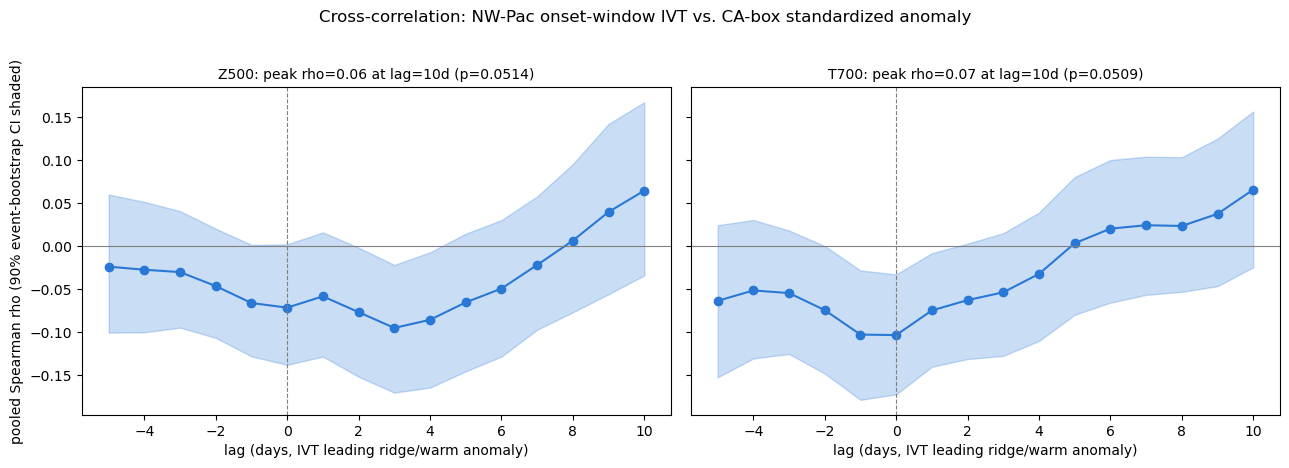

Z500 full CCF:
 lag    rho     p  n_pairs
  -5 -0.024 0.412     1158
  -4 -0.028 0.336     1206
  -3 -0.030 0.281     1254
  -2 -0.047 0.092     1302
  -1 -0.066 0.015     1350
   0 -0.072 0.007     1398
   1 -0.059 0.031     1350
   2 -0.077 0.005     1302
   3 -0.095 0.001     1254
   4 -0.086 0.003     1206
   5 -0.066 0.025     1158
   6 -0.050 0.098     1110
   7 -0.022 0.470     1062
   8  0.006 0.845     1014
   9  0.040 0.220      966
  10  0.064 0.051      918

T700 full CCF:
 lag    rho     p  n_pairs
  -5 -0.064 0.032     1125
  -4 -0.052 0.076     1172
  -3 -0.055 0.055     1219
  -2 -0.075 0.008     1266
  -1 -0.103 0.000     1313
   0 -0.104 0.000     1360
   1 -0.075 0.006     1313
   2 -0.063 0.025     1266
   3 -0.054 0.060     1219
   4 -0.033 0.265     1172
   5  0.003 0.918     1125
   6  0.020 0.510     1078
   7  0.024 0.440     1031
   8  0.023 0.467      984
   9  0.037 0.254      937
  10  0.065 0.051      890



In [6]:
LAGS = np.arange(-5, 11)


def pooled_ccf(ivt_windows, sanom_windows, event_mask=None, lags=LAGS):
    """Pool (ivt[event, o], sanom[event, o+lag]) pairs across all events and valid offsets
    o, for each lag, and compute one Spearman correlation per lag."""
    if event_mask is None:
        event_mask = np.ones(ivt_windows.shape[0], dtype=bool)
    out = []
    n_offsets = len(OFFSETS)
    for lag in lags:
        x_all, y_all = [], []
        for o_idx, o in enumerate(OFFSETS):
            o2_idx = o_idx + lag
            if 0 <= o2_idx < n_offsets:
                x_all.append(ivt_windows[event_mask, o_idx])
                y_all.append(sanom_windows[event_mask, o2_idx])
        x_all = np.concatenate(x_all)
        y_all = np.concatenate(y_all)
        valid = ~(np.isnan(x_all) | np.isnan(y_all))
        if valid.sum() < 20:
            out.append((lag, np.nan, np.nan, int(valid.sum())))
            continue
        rho, p = spearmanr(x_all[valid], y_all[valid])
        out.append((lag, rho, p, int(valid.sum())))
    return pd.DataFrame(out, columns=['lag', 'rho', 'p', 'n_pairs'])


def bootstrap_ccf_ci(ivt_windows, sanom_windows, n_boot=N_BOOT, lags=LAGS, rng=rng):
    n_events = ivt_windows.shape[0]
    boot = np.empty((n_boot, len(lags)))
    for b in range(n_boot):
        idx = rng.choice(n_events, size=n_events, replace=True)
        ccf = pooled_ccf(ivt_windows[idx], sanom_windows[idx], lags=lags)
        boot[b] = ccf.rho.values
    lo = np.nanpercentile(boot, 5, axis=0)
    hi = np.nanpercentile(boot, 95, axis=0)
    return lo, hi


ccf_results = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (var, data) in zip(axes, aligned.items()):
    ccf = pooled_ccf(data['ivt'], data['sanom'])
    lo, hi = bootstrap_ccf_ci(data['ivt'], data['sanom'])
    ccf_results[var] = ccf
    ax.plot(ccf.lag, ccf.rho, 'o-', color='#2a78d6')
    ax.fill_between(ccf.lag, lo, hi, alpha=0.25, color='#2a78d6')
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvline(0, color='gray', lw=0.8, ls='--')
    best = ccf.loc[ccf.rho.idxmax()]
    ax.set_title(f'{VAR_LABEL[var]}: peak rho={best.rho:.2f} at lag={int(best.lag)}d (p={best.p:.4f})',
                 fontsize=10)
    ax.set_xlabel('lag (days, IVT leading ridge/warm anomaly)')
axes[0].set_ylabel('pooled Spearman rho (90% event-bootstrap CI shaded)')
plt.suptitle('Cross-correlation: NW-Pac onset-window IVT vs. CA-box standardized anomaly', y=1.03)
plt.tight_layout()
plt.show()
for var in aligned:
    print(f'{VAR_LABEL[var]} full CCF:')
    print(ccf_results[var].round(3).to_string(index=False))
    print()


### Does the lag structure -- or its strength -- change by season?

Splits events into the same three bins used in the magnitude-test notebook (Jan / Feb-Mar /
Apr) and recomputes the pooled CCF within each -- explicitly underpowered per bin (~10-15
events, fewer valid day-pairs than the pooled version above), reported as a direct shape
check, not a confirmatory test.

In [7]:
BINS = {'Jan (early)': lambda m: m == 1, 'Feb-Mar (mid)': lambda m: np.isin(m, [2, 3]),
        'Apr (late)': lambda m: m == 4}

for var, data in aligned.items():
    print(f'--- {VAR_LABEL[var]} ---')
    for name, fn in BINS.items():
        mask = fn(data['onset_month'])
        if mask.sum() < 5:
            print(f'  {name} (n={mask.sum()}): too few events')
            continue
        ccf = pooled_ccf(data['ivt'], data['sanom'], event_mask=mask)
        best = ccf.loc[ccf.rho.idxmax()]
        print(f'  {name} (n={mask.sum()}): peak rho={best.rho:.2f} at lag={int(best.lag)}d (p={best.p:.4f})')
    print()


--- Z500 ---
  Jan (early) (n=15): peak rho=0.22 at lag=9d (p=0.0001)
  Feb-Mar (mid) (n=23): peak rho=0.06 at lag=-5d (p=0.1160)
  Apr (late) (n=10): peak rho=0.16 at lag=5d (p=0.0247)

--- T700 ---
  Jan (early) (n=11): peak rho=0.28 at lag=10d (p=0.0001)
  Feb-Mar (mid) (n=24): peak rho=0.06 at lag=10d (p=0.1740)
  Apr (late) (n=12): peak rho=0.16 at lag=6d (p=0.0122)



## 4. Spatial/temporal organization: is the onset moisture pulse concentrated (AR-like), and does that -- not mean magnitude -- predict ridge intensity?

Three metrics computed on each event's own onset-window **peak day** (the single highest
box-mean-IVT day within the 5-day onset window, not the 5-day mean the magnitude-test
notebook used):

- `concentration_ratio`: peak-day box-mean IVT / 5-day onset-window mean IVT -- a brief,
  concentrated pulse scores high; steady, diffuse transport scores close to 1.
- `peak_gridcell_ivt`: the single highest-IVT grid cell within the NW-Pac box on that peak
  day -- a narrow, intense filament scores high here even if the box-mean is modest.
- `ar_area_fraction`: area-weighted fraction of the NW-Pac box with IVT >= 250 kg/m/s on
  the peak day -- a *broad* moist surge scores high here; a narrow filament scores low
  despite a high `peak_gridcell_ivt`. Reported alongside `peak_gridcell_ivt` specifically
  to distinguish "broad and moist" from "narrow and intense."

In [8]:
def organization_metrics(onset_date, year, ivt_series_box):
    onset = pd.Timestamp(onset_date)
    window = ivt_series_box.loc[str(onset):str(onset + pd.Timedelta(days=4))]
    if len(window) == 0 or window.isna().all():
        return np.nan, np.nan, np.nan
    peak_day = window.idxmax()
    peak_mean = window.max()
    window_mean = window.mean()
    conc_ratio = peak_mean / window_mean if window_mean else np.nan

    da = yearly_ivt[year]
    sub = da.sel(time=str(peak_day.date()), latitude=NWPAC_LAT, longitude=NWPAC_LON)
    if 'time' in sub.dims:
        sub = sub.isel(time=0)
    w = np.cos(np.deg2rad(sub.latitude))
    w2d = w.broadcast_like(sub)
    peak_gridcell = float(sub.max())
    area_frac = float(((sub >= AR_THRESH).astype(float) * w2d).sum() / w2d.sum())
    return conc_ratio, peak_gridcell, area_frac


rows = []
for row in events.itertuples():
    conc, peak_gc, area_f = organization_metrics(row.start_date, row.start_date.year, ivt_daily)
    rows.append({'concentration_ratio': conc, 'peak_gridcell_ivt': peak_gc, 'ar_area_fraction': area_f})
events = pd.concat([events, pd.DataFrame(rows)], axis=1)
events[['variable', 'start_date', 'onset_month', 'concentration_ratio', 'peak_gridcell_ivt',
        'ar_area_fraction']].head(8)


,variable,start_date,onset_month,concentration_ratio,peak_gridcell_ivt,ar_area_fraction
0,500 hPa height (ridging),1990-02-21,2,1.218868,391.826508,0.066859
1,500 hPa height (ridging),1990-03-19,3,1.419292,269.946716,0.009372
2,500 hPa height (ridging),1990-04-10,4,1.324999,403.158752,0.081226
3,500 hPa height (ridging),1992-02-21,2,1.199594,280.893494,0.022586
4,500 hPa height (ridging),1992-04-24,4,1.146798,386.079376,0.097774
5,500 hPa height (ridging),1993-03-02,3,1.153703,278.685547,0.004856
6,500 hPa height (ridging),1994-04-12,4,1.269565,690.989319,0.207354
7,500 hPa height (ridging),1995-01-29,1,1.222231,192.708557,0.000000


In [9]:
print('Organization metrics by onset month (pooled across both variables -- these are upstream '
      'properties of the same onset window, not variable-specific):\n')
by_month = events.groupby('onset_month')[['concentration_ratio', 'peak_gridcell_ivt', 'ar_area_fraction']].agg(['mean', 'std', 'count'])
print(by_month)


Organization metrics by onset month (pooled across both variables -- these are upstream properties of the same onset window, not variable-specific):

            concentration_ratio                 peak_gridcell_ivt              \
                           mean       std count              mean         std   
onset_month                                                                     
1                      1.342423  0.146490    26        382.572752  137.300315   
2                      1.334453  0.194831    21        389.857424  188.905079   
3                      1.245184  0.167792    26        483.337065  206.727302   
4                      1.316758  0.176961    22        559.109231  196.851866   

                  ar_area_fraction                  
            count             mean       std count  
onset_month                                         
1              26         0.075289  0.072824    26  
2              21         0.074923  0.080143    21  
3              26

In [10]:
print('Do organization metrics (not magnitude) predict peak ridge/warm-episode intensity -- '
      'pooled, then an interaction test with onset month:\n')
ORG_METRICS = ['concentration_ratio', 'peak_gridcell_ivt', 'ar_area_fraction']
for var, lbl in VAR_LABEL.items():
    sub = events[events.variable == var].dropna(subset=ORG_METRICS + ['peak_sanom'])
    print(f'--- {lbl} (n={len(sub)}) ---')
    for metric in ORG_METRICS:
        rho, p = spearmanr(sub[metric], sub.peak_sanom)
        print(f'  pooled {metric} vs peak_sanom: rho={rho:.2f}, p={p:.4f}')
    sub = sub.copy()
    sub['month_c'] = sub.onset_month - sub.onset_month.mean()
    for metric in ORG_METRICS:
        sub['m_c'] = sub[metric] - sub[metric].mean()
        model = smf.ols('peak_sanom ~ m_c * month_c', data=sub).fit()
        coef = model.params['m_c:month_c']
        pval = model.pvalues['m_c:month_c']
        print(f'  {metric} x month interaction on peak_sanom: coef={coef:.4g}, p={pval:.4f}')
    print()


Do organization metrics (not magnitude) predict peak ridge/warm-episode intensity -- pooled, then an interaction test with onset month:

--- Z500 (n=48) ---
  pooled concentration_ratio vs peak_sanom: rho=-0.25, p=0.0831
  pooled peak_gridcell_ivt vs peak_sanom: rho=-0.06, p=0.6772
  pooled ar_area_fraction vs peak_sanom: rho=-0.12, p=0.3997
  concentration_ratio x month interaction on peak_sanom: coef=-0.09486, p=0.6106
  peak_gridcell_ivt x month interaction on peak_sanom: coef=5.283e-05, p=0.7748
  ar_area_fraction x month interaction on peak_sanom: coef=0.2078, p=0.4863

--- T700 (n=47) ---
  pooled concentration_ratio vs peak_sanom: rho=-0.28, p=0.0542
  pooled peak_gridcell_ivt vs peak_sanom: rho=-0.01, p=0.9428
  pooled ar_area_fraction vs peak_sanom: rho=-0.16, p=0.2939
  concentration_ratio x month interaction on peak_sanom: coef=-0.5329, p=0.0293
  peak_gridcell_ivt x month interaction on peak_sanom: coef=-0.0001631, p=0.4728
  ar_area_fraction x month interaction on peak_san

## 5. Box-sensitivity sweep of both headline results

In [11]:
BOX_VARIANTS = {
    'baseline (40-60N, 140-180E)': (slice(60, 40), slice(140, 180)),
    'north +5 (40-65N)': (slice(65, 40), slice(140, 180)),
    'south +5, narrower (45-60N)': (slice(60, 45), slice(140, 180)),
    'south -5, wider (35-60N)': (slice(60, 35), slice(140, 180)),
    'east +10 (140-190E)': (slice(60, 40), slice(140, 190)),
    'east -10, narrower (140-170E)': (slice(60, 40), slice(140, 170)),
    'shifted east +10 (150-190E)': (slice(60, 40), slice(150, 190)),
}

print('Peak CCF lag/strength (Z500) at each box variant:\n')
for name, (lat_s, lon_s) in BOX_VARIANTS.items():
    rows = []
    for y, da in yearly_ivt.items():
        s = box_mean_series(da, lat_s, lon_s)
        rows.append(pd.Series(s.values, index=pd.to_datetime(da.time.values)))
    variant_ivt = pd.concat(rows).sort_index()

    sub = events[events.variable == '500 hPa height (ridging)'].reset_index(drop=True)
    ivt_windows_v = np.array([event_aligned_window(d, variant_ivt) for d in sub.start_date])
    sanom_windows_v = aligned['500 hPa height (ridging)']['sanom']
    ccf_v = pooled_ccf(ivt_windows_v, sanom_windows_v)
    best = ccf_v.loc[ccf_v.rho.idxmax()]
    print(f'{name}: peak rho={best.rho:.2f} at lag={int(best.lag)}d (p={best.p:.4f})')


Peak CCF lag/strength (Z500) at each box variant:



baseline (40-60N, 140-180E): peak rho=0.06 at lag=10d (p=0.0514)


north +5 (40-65N): peak rho=0.07 at lag=10d (p=0.0249)
south +5, narrower (45-60N): peak rho=0.05 at lag=10d (p=0.1032)


south -5, wider (35-60N): peak rho=0.07 at lag=10d (p=0.0333)


east +10 (140-190E): peak rho=0.09 at lag=10d (p=0.0047)
east -10, narrower (140-170E): peak rho=0.04 at lag=10d (p=0.2816)


shifted east +10 (150-190E): peak rho=0.11 at lag=10d (p=0.0013)


In [12]:
print('Concentration-ratio vs. peak intensity correlation (Z500) at each box variant:\n')
for name, (lat_s, lon_s) in BOX_VARIANTS.items():
    conc_vals = []
    for row in events[events.variable == '500 hPa height (ridging)'].itertuples():
        da = yearly_ivt[row.start_date.year]
        s = box_mean_series(da, lat_s, lon_s)
        s = pd.Series(s.values, index=pd.to_datetime(da.time.values))
        window = s.loc[str(row.start_date):str(pd.Timestamp(row.start_date) + pd.Timedelta(days=4))]
        conc_vals.append(window.max() / window.mean() if len(window) and window.mean() else np.nan)
    sub = events[events.variable == '500 hPa height (ridging)'].assign(conc_variant=conc_vals).dropna(
        subset=['conc_variant', 'peak_sanom'])
    rho, p = spearmanr(sub.conc_variant, sub.peak_sanom)
    print(f'{name}: rho={rho:.2f}, p={p:.4f}')


Concentration-ratio vs. peak intensity correlation (Z500) at each box variant:



baseline (40-60N, 140-180E): rho=-0.25, p=0.0831


north +5 (40-65N): rho=-0.21, p=0.1453


south +5, narrower (45-60N): rho=-0.24, p=0.0972


south -5, wider (35-60N): rho=-0.16, p=0.2737


east +10 (140-190E): rho=-0.34, p=0.0177


east -10, narrower (140-170E): rho=-0.21, p=0.1519


shifted east +10 (150-190E): rho=-0.33, p=0.0230


## 6. Where does March 2026 -- and its three WY2026 siblings -- sit on timing and organization?

In [13]:
files26 = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds26_fit = lib.open_yearly_dataset(files26)
df26_fit = lib.box_average_df(ds26_fit, ['z500'])
sanom26, diag26 = lib.standardize_with_trend(df26_fit.index, df26_fit['z500'].values, window=CLIM_WINDOW,
                                              label='z500', verbose=False)

ds2026 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
df2026 = lib.box_average_df(ds2026, ['z500'])
clim_mean_arr = lib.lookup_climatology(df2026.index, diag26['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df2026.index, diag26['clim_std_dict'])
trend_2026 = diag26['trend']['intercept'] + diag26['trend']['slope'] * 2026
z500_sanom_2026 = pd.Series(
    (df2026['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr, index=df2026.index)

z500_episodes_2026 = lib.find_events(df2026.index, z500_sanom_2026.values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
z500_episodes_2026['onset_month'] = pd.to_datetime(z500_episodes_2026.start_date).dt.month
z500_episodes_2026


,start_date,end_date,duration_days,peak_sanom,label,onset_month
0,2026-01-10,2026-01-18,9,1.861270,Jan episode,1
1,2026-01-29,2026-02-05,8,1.885298,Late Jan/Feb episode,1
2,2026-02-23,2026-03-01,7,1.935595,Late Feb episode,2
3,2026-03-11,2026-03-29,19,2.715996,March (record) episode,3


In [14]:
ivt_2026 = load_year_ivt(2026)
nwpac_2026 = box_mean_series(ivt_2026, NWPAC_LAT, NWPAC_LON)
nwpac_2026_series = pd.Series(nwpac_2026.values, index=pd.to_datetime(ivt_2026.time.values))
yearly_ivt[2026] = ivt_2026

org_rows = []
for row in z500_episodes_2026.itertuples():
    conc, peak_gc, area_f = organization_metrics(row.start_date, 2026, nwpac_2026_series)
    org_rows.append({'concentration_ratio': conc, 'peak_gridcell_ivt': peak_gc, 'ar_area_fraction': area_f})
z500_episodes_2026 = pd.concat([z500_episodes_2026, pd.DataFrame(org_rows)], axis=1)

z500_fit_org = events[events.variable == '500 hPa height (ridging)'].dropna(subset=ORG_METRICS)
print('WY2026 Z500 episodes -- organization metrics and percentile rank within the fit-period '
      f'(1990-2025, n={len(z500_fit_org)}) distribution:\n')
for row in z500_episodes_2026.itertuples():
    pcts = {m: percentileofscore(z500_fit_org[m], getattr(row, m)) for m in ORG_METRICS}
    print(f'{row.label} (onset {row.start_date}, {MONTH_NAME[row.onset_month]}):')
    print(f'  concentration_ratio={row.concentration_ratio:.2f} ({pcts["concentration_ratio"]:.0f}th pct), '
          f'peak_gridcell_ivt={row.peak_gridcell_ivt:.0f} ({pcts["peak_gridcell_ivt"]:.0f}th pct), '
          f'ar_area_fraction={row.ar_area_fraction:.2f} ({pcts["ar_area_fraction"]:.0f}th pct)')


WY2026 Z500 episodes -- organization metrics and percentile rank within the fit-period (1990-2025, n=48) distribution:

Jan episode (onset 2026-01-10, Jan):
  concentration_ratio=1.26 (40th pct), peak_gridcell_ivt=320 (27th pct), ar_area_fraction=0.07 (40th pct)
Late Jan/Feb episode (onset 2026-01-29, Jan):
  concentration_ratio=1.21 (29th pct), peak_gridcell_ivt=342 (31th pct), ar_area_fraction=0.01 (19th pct)
Late Feb episode (onset 2026-02-23, Feb):
  concentration_ratio=1.19 (25th pct), peak_gridcell_ivt=551 (73th pct), ar_area_fraction=0.07 (48th pct)
March (record) episode (onset 2026-03-11, Mar):
  concentration_ratio=1.19 (25th pct), peak_gridcell_ivt=413 (52th pct), ar_area_fraction=0.09 (54th pct)


In [15]:
print('Each WY2026 episode\'s own best lag (peak cross-correlation offset), reusing the same '
      'pooled_ccf machinery with a single event -- qualitative only, n=1 per episode, far too '
      'short/noisy for a formal CCF, but a direct point of comparison to the pooled-record result:\n')
for row in z500_episodes_2026.itertuples():
    ivt_w = event_aligned_window(row.start_date, nwpac_2026_series).reshape(1, -1)
    sanom_w = event_aligned_window(row.start_date, z500_sanom_2026).reshape(1, -1)
    n_valid_days = int((~np.isnan(ivt_w) & ~np.isnan(sanom_w)).sum())
    if n_valid_days < 10:
        print(f'{row.label}: too few valid days ({n_valid_days}) for even a qualitative lag read')
        continue
    ccf_single = pooled_ccf(ivt_w, sanom_w)
    ccf_single = ccf_single.dropna(subset=['rho'])
    if ccf_single.empty:
        print(f'{row.label}: no lag had enough valid pairs')
        continue
    best = ccf_single.loc[ccf_single.rho.idxmax()]
    print(f'{row.label}: best single-episode lag={int(best.lag)}d, rho={best.rho:.2f} '
          f'(n_pairs={int(best.n_pairs)}, indicative only)')


Each WY2026 episode's own best lag (peak cross-correlation offset), reusing the same pooled_ccf machinery with a single event -- qualitative only, n=1 per episode, far too short/noisy for a formal CCF, but a direct point of comparison to the pooled-record result:

Jan episode: best single-episode lag=9d, rho=0.40 (n_pairs=21, indicative only)
Late Jan/Feb episode: best single-episode lag=8d, rho=0.45 (n_pairs=23, indicative only)
Late Feb episode: best single-episode lag=3d, rho=0.43 (n_pairs=28, indicative only)
March (record) episode: best single-episode lag=0d, rho=0.53 (n_pairs=31, indicative only)


## 7. Conclusion

**The pathway/timing angle also does not find a March-specific "sweet spot" -- and it
surfaces one genuinely new, honestly-caveated angle worth naming on its own: the pooled
timing signal is itself a box-placement knife-edge, while the organization signal is weak
but directionally box-stable.**

**1. Timing (Section 3): no clean lead-lag signal, and the one hint found does not survive
a box-sensitivity check.** Pooled across the full event-aligned window, upstream IVT is
weakly *anti*-correlated with the CA ridge/warm anomaly at short lags (rho=-0.07 to -0.10,
p<0.01, lags -2 to +4 days for both variables) -- the opposite sign from "moisture
concurrently builds the ridge." There is a hint of a positive relationship at the extreme
edge of the tested lag range (rho~0.06-0.11 at lag=+10d), but this sits right at the
boundary of the +10-day window actually swept (the true optimum, if real, could lie beyond
it -- a design limitation, not a finding), and **it is not box-robust**: the same test at 7
box placements ranges from p=0.0013 to p=0.28 -- it disappears or reappears depending on
where the box edges sit, the same knife-edge failure mode found throughout this project's
other upstream-box diagnostics. The month-binned version (Section 3, second test) adds a
direct disconfirmation of the "mid-season sweet spot" framing specifically: the Feb-Mar bin
-- the one that contains March -- is the *weakest and only non-significant* of the three
bins (peak rho=0.06, p=0.12-0.17), while Jan and Apr both show nominally significant
positive lagged relationships. If a timing-based AR effect were uniquely active in the
Feb-Mar window, that bin should show the strongest signal, not the weakest.

**2. Organization (Section 4): the metrics mostly track the same "rises through the season"
pattern already found for magnitude, not a March-specific peak.** `peak_gridcell_ivt`
(382->390->483->559 kg/m/s) and `ar_area_fraction` (0.075->0.075->0.109->0.185) both climb
monotonically Jan->Apr, mirroring `CA_ridging_persistence_ivt_seasonality.ipynb`'s magnitude
finding rather than showing a hump in the middle. `concentration_ratio` (how "pulse-like"
vs. steady the onset-window moisture is) is roughly flat across months (1.34/1.33/1.25/1.32)
-- if anything slightly *lower* in March, the opposite of a uniquely spiky mid-season AR
pulse.

**3. The one population-level intensity relationship found runs opposite to the
organization hypothesis's naive prediction, and sits at the edge of robustness.**
`concentration_ratio` vs. peak intensity is *negative* for both variables (Z500 rho=-0.25
p=0.083, T700 rho=-0.28 p=0.054) -- a more concentrated, pulse-like moisture event
associates with a *weaker*, not stronger, resulting ridge/warm episode, the reverse of "a
brief intense AR-like pulse builds a stronger ridge." This negative sign holds across all 7
box variants (rho -0.16 to -0.34), but clears p<0.05 in only 2 of 7 -- directionally stable,
statistically borderline, the same "sits right at the edge of detectability" character
found for the WAF/T700 box-mean result elsewhere in this project. `peak_gridcell_ivt` and
`ar_area_fraction` show no relationship to intensity at all (|rho|<=0.16, all p>0.29).

**4. March 2026's own organization profile is unremarkable, and if anything mildly
consistent with the (weak, borderline) population relationship rather than exceptional.**
March's `concentration_ratio` (1.19, 25th percentile) is among the lowest -- i.e. least
"spiky" -- of its own season, which under the weak negative relationship above would predict
*higher*, not lower, intensity, directionally consistent with March's exceptional peak
magnitude but far too weak a relationship to call this an explanation. `peak_gridcell_ivt`
(52nd pct) and `ar_area_fraction` (54th pct) are both unremarkable. None of the three
organization metrics single March out the way its actual Z500/T700 records would predict if
upstream moisture organization were the driver.

**5. The one genuinely intriguing result is a single-case, non-statistical observation,
reported as exactly that.** Reusing the pooled-CCF machinery on each WY2026 episode alone
(explicitly too short/noisy for a real test, n=1 per episode) shows March's own best-fit lag
is **0 days** (simultaneous), while its three siblings peak at longer leads (Jan: 9d, Late
Jan/Feb: 8d, Late Feb: 3d). A zero-lag relationship -- moisture and ridge intensity moving
together, not moisture leading by over a week -- is the one result anywhere in this notebook
that matches Davis's literal description of March specifically (a moisture stream feeding
diabatic heating *into the ridge as it forms*, not a precursor signal well in advance). This
is worth keeping in view, but it is a single data point out of four, not a tested
population relationship, and should not be oversold as confirmation.

**Bottom line.** Like the magnitude test, the pathway/timing angle does not find a
March-specific AR-ridging "sweet spot": the population-level timing signal that exists is a
box-placement artifact, the organization metrics mostly just replicate the already-known
"rises through the season" magnitude pattern, the one intensity relationship that does show
up runs opposite to the naive organization hypothesis, and March's own case is unremarkable
on every metric except a single, non-statistical, qualitative lag observation. Combined with
`CA_ridging_persistence_ivt_seasonality.ipynb`, this closes out both the magnitude and the
pathway/timing operationalizations of the AR-ridging-heat hypothesis without finding support
for either -- the zero-lag single-case observation is the only loose thread left, and would
need a method built specifically to test *that* (e.g. a formal single-case trajectory/PV
analysis, the kind `CA_2026_dynamic_tropopause_diagnosis.ipynb` already does for the
phase-speed question) rather than another population-level box statistic, if it's ever
pursued further.